<style>
/* Readable in classic Notebook, JupyterLab, and most HTML exports. */
.jp-RenderedHTMLCommon h1, .text_cell_render h1 { font-size: 35px !important; line-height: 1.35 !important; margin-top: 24px !important; }
.jp-RenderedHTMLCommon h2, .text_cell_render h2 { font-size: 28px !important; line-height: 1.36 !important; margin-top: 24px !important; }
.jp-RenderedHTMLCommon h3, .text_cell_render h3 { font-size: 22px !important; line-height: 1.4 !important; }
.jp-RenderedHTMLCommon p, .jp-RenderedHTMLCommon li, .text_cell_render p, .text_cell_render li { font-size: 17px !important; line-height: 1.65 !important; }
.jp-RenderedHTMLCommon code, .text_cell_render code { font-size: 0.94em !important; }
.jp-RenderedHTMLCommon table, .text_cell_render table { font-size: 16px !important; }
</style>

# Matplotlib From ZERO — Learn, See, Practise 🎨

### 2 tiny datasets • 14 plot topics • 5 questions per topic • 75 questions total

**Your goal:** read one very short explanation → run one **worked example** → solve **five new questions by yourself**.

This is designed for someone using Matplotlib for the **very first time**. There are no hidden datasets and you do not need to download any CSV from the internet.

<div style="background:#E6F7F1;border-left:6px solid #16866C;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">START HERE</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">The notebook creates its own data</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">Run the setup cell once. It creates exactly TWO tiny CSV files inside a local folder, loads them with Pandas, and makes all later questions ready to solve.</div>
</div>

## How to use this notebook

1. Run cells **from top to bottom** using **Shift + Enter**.
2. **Look at the example chart** in each topic. You may copy its structure, but change the data and styling for each question.
3. Under every question there is an empty **YOUR CODE** cell. Write your own answer there, then run it.
4. An optional **Hint** is folded under each question. Open only when needed.
5. Every task spells out **the columns to extract, the chart to draw, colors, labels, and one small extra condition**.

**Important:** Questions are intentionally **unsolved**. The worked examples teach each technique; you create the 75 answers.

### The 3-step formula used everywhere

`1. Extract data` → `2. Draw the chart` → `3. Add a title + labels + show()`

For example: `x = shop["day"]`, `y = shop["apples"]`, then `plt.plot(x, y)`.

> Install once if you need to: `pip install matplotlib pandas numpy`. In Google Colab, these libraries are normally available.

# 00 · Setup — Two Very Small Datasets

**Dataset A: Weekly Fruit Shop** — 7 days and 6 simple columns. Use it for product sales, customers, and simple daily trends.

**Dataset B: Student Marks** — 10 students and 5 simple columns. Use it for marks, study hours, distributions, comparisons, and heatmaps.

**What the columns mean**

| Variable | Columns | Meaning |
|---|---|---|
| `shop` | `day`, `apples`, `bananas`, `oranges`, `customers`, `revenue` | Daily fruit units sold, number of customers, total revenue in simple currency units |
| `students` | `student`, `hours`, `math`, `english`, `science` | First name, study hours, and marks out of 100 |

The numbers are fictional and deliberately easy to read.

In [2]:
# RUN THIS FIRST — creates the datasets. No separate files needed.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Slightly larger default charts and text so plots are easy to read.
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# Make a local folder for the TWO CSV datasets.
data_folder = Path("matplotlib_practice_data")
data_folder.mkdir(exist_ok=True)

# Dataset A: 7 rows. A day is one row.
shop_source = pd.DataFrame({
    "day": ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    "apples": [8, 10, 7, 12, 11, 15, 14],
    "bananas": [5, 7, 6, 8, 9, 11, 10],
    "oranges": [4, 3, 5, 6, 5, 8, 7],
    "customers": [25, 28, 24, 32, 35, 42, 40],
    "revenue": [200, 240, 210, 300, 330, 400, 385],
})

# Dataset B: 10 rows. A student is one row.
student_source = pd.DataFrame({
    "student": ["Asha", "Bina", "Chetan", "Dev", "Esha", "Farah", "Gita", "Hari", "Isha", "Jai"],
    "hours": [1, 2, 2, 3, 4, 4, 5, 5, 6, 7],
    "math": [45, 50, 55, 62, 68, 73, 80, 78, 88, 94],
    "english": [52, 58, 60, 65, 70, 76, 74, 85, 90, 92],
    "science": [48, 53, 57, 64, 69, 72, 82, 80, 87, 95],
})

# Save once: this also teaches how to create your own CSV datasets.
shop_source.to_csv(data_folder / "weekly_shop.csv", index=False)
student_source.to_csv(data_folder / "student_marks.csv", index=False)

# Load CSV files using Pandas. We will use these two variables everywhere.
shop = pd.read_csv(data_folder / "weekly_shop.csv")
students = pd.read_csv(data_folder / "student_marks.csv")

print("✅ Data is ready! Folder:", data_folder.resolve())
print("\n--- WEEKLY FRUIT SHOP ---")
print(shop.to_string(index=False))
print("\n--- STUDENT MARKS ---")
print(students.to_string(index=False))

✅ Data is ready! Folder: C:\Users\Prashant Ojha\Documents\DataAnalytics classes\python\pandas\matplotlib_practice_data\matplotlib_practice_data

--- WEEKLY FRUIT SHOP ---
day  apples  bananas  oranges  customers  revenue
Mon       8        5        4         25      200
Tue      10        7        3         28      240
Wed       7        6        5         24      210
Thu      12        8        6         32      300
Fri      11        9        5         35      330
Sat      15       11        8         42      400
Sun      14       10        7         40      385

--- STUDENT MARKS ---
student  hours  math  english  science
   Asha      1    45       52       48
   Bina      2    50       58       53
 Chetan      2    55       60       57
    Dev      3    62       65       64
   Esha      4    68       70       69
  Farah      4    73       76       72
   Gita      5    80       74       82
   Hari      5    78       85       80
   Isha      6    88       90       87
    Jai      7  

## First, learn the words

- **`x` values:** labels or numbers placed from left to right (e.g. days or study hours).
- **`y` values:** measured numbers placed up the chart (e.g. apples sold).
- **`plt`**: short name for `matplotlib.pyplot`, the chart-drawing module.
- **`figsize=(8, 4)`**: chart width and height in inches.
- **`color="blue"`**: chart color; you can also use named colors such as `tomato`, `teal`, `orange`, and `purple`.
- **`label="Apples"`**: the name shown when you call `plt.legend()`.
- **`plt.show()`**: display the chart.

You will practise these again in nearly every topic.

# 01 · Extract & Prepare Data — Before Plotting

**A chart needs data first.** In Pandas, a *column* is obtained with `df["column"]` and multiple columns with `df[["col1", "col2"]]`.

## The eight operations you will reuse

| Goal | Syntax | What it returns |
|---|---|---|
| One column | `shop["apples"]` | 7 apple values |
| Two columns | `shop[["day", "apples"]]` | A small two-column table |
| First 3 rows | `shop.head(3)` | Monday–Wednesday |
| First 4 rows | `shop.iloc[:4]` | Positions 0, 1, 2, 3 |
| Filter values | `students[students["math"] >= 70]` | Students with math marks at least 70 |
| Add a column | `shop["fruit_total"] = shop["apples"] + shop["bananas"] + shop["oranges"]` | A new column |
| Total or average | `shop["apples"].sum()`, `students["math"].mean()` | One number |
| Sort rows | `students.sort_values("math", ascending=False)` | Highest marks first |

**Easy rule:** `df["a"]` gives **one series**; `df[["a", "b"]]` gives **a DataFrame with two columns**.

In [3]:
# Worked example — read a column, filter rows, and calculate values.
days = shop["day"]                  # x labels (Mon, Tue, ...)
apple_sales = shop["apples"]         # 7 y values

first_three_days = shop.iloc[:3]    # Mon, Tue, Wed
high_math = students[students["math"] >= 70]

# Add a new column. This will be available in later practice questions.
shop["fruit_total"] = shop["apples"] + shop["bananas"] + shop["oranges"]

print("Days:", days.tolist())
print("Apple sales:", apple_sales.tolist())
print("First 3 days: ", first_three_days["day"].tolist())
print("Weekly apples sold:", shop["apples"].sum())
print("Average math mark:", round(students["math"].mean(), 1))
print("Total fruit each day:", shop["fruit_total"].tolist())
print("Students with math >= 70:", high_math["student"].tolist())

Days: ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
Apple sales: [8, 10, 7, 12, 11, 15, 14]
First 3 days:  ['Mon', 'Tue', 'Wed']
Weekly apples sold: 77
Average math mark: 69.3
Total fruit each day: [17, 20, 18, 26, 25, 34, 31]
Students with math >= 70: ['Farah', 'Gita', 'Hari', 'Isha', 'Jai']


## 5 tiny warm-up questions — No charts yet

**Do these first**. Use `print()` to see your answers. They teach the extraction skills used in the plots.

### Warm-up W1 — Select one column

**Do:** Extract `day` and `customers` separately from `shop`. Print both as lists.

<details><summary>💡 Small hint</summary>

Use `shop["column"].tolist()`.

</details>

In [ ]:
# W1 — YOUR CODE (practice)
display(shop['day'].tolist())
display(shop['customers'].tolist())


# Select one column



# Write your Pandas code and print the answer below.

['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

[25, 28, 24, 32, 35, 42, 40]

### Warm-up W2 — Find a total

**Do:** Extract the `bananas` column from `shop`. Print the **total bananas** sold in 7 days.

<details><summary>💡 Small hint</summary>

Use `.sum()`.

</details>

In [108]:
# W2 — YOUR CODE (practice)
print('Number of bananas sold in last 7 days: ',shop[['bananas']].sum())
# Find a total
# Write your Pandas code and print the answer below.

Number of bananas sold in last 7 days:  bananas    56
dtype: int64


### Warm-up W3 — Choose the first rows

**Do:** Extract only the **first 4 students** with `.iloc` and print their `student` and `math` columns.

<details><summary>💡 Small hint</summary>

First four rows: `.iloc[:4]`.

</details>

In [ ]:
# W3 — YOUR CODE (practice)

students.iloc[:4,][['student', 'math']]
# Choose the first rows
# Write your Pandas code and print the answer below.

,student,math
0,Asha,45
1,Bina,50
2,Chetan,55
3,Dev,62


### Warm-up W4 — Filter rows

**Do:** Find and print the `student` and `science` columns **only for students with science ≥ 80**.

<details><summary>💡 Small hint</summary>

Filter first, then select two columns.

</details>

In [121]:
# W4 — YOUR CODE (practice)
# Filter rows
# Write your Pandas code and print the answer below.
students[
    students['science'] >=80
][['student', 'science']]

,student,science
6,Gita,82
7,Hari,80
8,Isha,87
9,Jai,95


### Warm-up W5 — Sort and select

**Do:** Sort `students` by `english` marks from **highest to lowest**, then print the **top 3** names and marks.

<details><summary>💡 Small hint</summary>

Try `.sort_values(..., ascending=False).head(3)`.

</details>

In [ ]:
# W5 — YOUR CODE (practice)
# Sort and select
# Write your Pandas code and print the answer below.
students['english'].sort_values(ascending=False).head(3)

# both methods can be used for this one
students.sort_values(by='english', ascending=False).head(3)

,student,hours,math,english,science
9,Jai,7,94,92,95
8,Isha,6,88,90,87
7,Hari,5,78,85,80


# 02 · Plot Practice — 14 Essential Chart Topics

For each topic: **What it shows → Main function → Worked example → 5 unsolved questions**.

**Every plot must be readable**. Unless a question says otherwise, write `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)`, `plt.tight_layout()`, and `plt.show()`. For pie charts and heatmaps, use the titles and labels that make sense for those plot types.

**Question difficulty:** ① a direct chart → ② a small change → ③ another column or subset → ④ new feature → ⑤ combine two simple ideas.

---

# Plot 01 · 📈 Basic Line Chart

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> See how ONE numeric value changes across ordered days.</div>

**Main syntax:** `plt.plot(x, y, color="blue", marker="o")`

**Learn it:** Use `x = shop["day"]` for day labels and `y = shop["apples"]` for apple counts. A line connects points in day order. `marker="o"` makes each point visible.

## Worked example — run this cell first

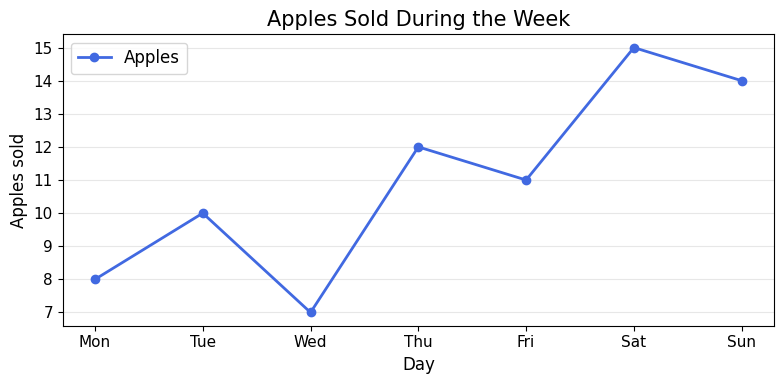

In [124]:
# WORKED EXAMPLE: One line chart — daily apples
x = shop["day"]        # Extract the day column for horizontal labels
y = shop["apples"]     # Extract the number of apples for vertical values

plt.figure(figsize=(8, 4))
plt.plot(x, y, color="royalblue", marker="o", linewidth=2, label="Apples")
plt.title("Apples Sold During the Week")
plt.xlabel("Day")
plt.ylabel("Apples sold")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 01

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 1.1 — Banana trend

- **1 · Extract:** `shop["day"]` → x; `shop["bananas"]` → y.
- **2 · Draw:** One **line** for bananas across all 7 days.
- **3 · Exact style:** Green solid line, circle (`o`) markers, linewidth 2.
- **4 · Titles/labels:** Title **Bananas Each Day**; x **Day**; y **Bananas sold**.
- **5 · Also do this:** Show a y-axis grid.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.plot(x, y, ...)`.

</details>

In [ ]:
# Question 1.1 — BANANA TREND
# Step 1: Select the requested data from shop or students.
x = shop['day']
y = shop['banana']
# Step 2: Create the specified chart with the specified color/style.
plt.plot(x, y )
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 1.2 — Customer trend

- **1 · Extract:** `shop["day"]` and `shop["customers"]`.
- **2 · Draw:** One line chart across all 7 days.
- **3 · Exact style:** Purple line, square (`s`) markers.
- **4 · Titles/labels:** Title **Daily Customers**; x **Day**; y **Customers**.
- **5 · Also do this:** Do not add a legend.

<details><summary>💡 Show a small hint only if needed</summary>

Try `marker="s"`.

</details>

In [11]:
# Question 1.2 — CUSTOMER TREND
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 1.3 — Revenue over time

- **1 · Extract:** `shop["day"]` and `shop["revenue"]`.
- **2 · Draw:** One line.
- **3 · Exact style:** Orange dashed line (`--`), circle markers.
- **4 · Titles/labels:** Title **Weekly Revenue**; x **Day**; y **Revenue**.
- **5 · Also do this:** Add a horizontal grid and a legend called **Revenue**.

<details><summary>💡 Show a small hint only if needed</summary>

Try `linestyle="--"` and `label="Revenue"`.

</details>

In [12]:
# Question 1.3 — REVENUE OVER TIME
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 1.4 — First four days only

- **1 · Extract:** `shop.iloc[:4]`, then its `day` and `oranges` columns.
- **2 · Draw:** One line for **Mon–Thu only**.
- **3 · Exact style:** Tomato-red line, diamond (`D`) markers.
- **4 · Titles/labels:** Title **Oranges: First Four Days**; x **Day**; y **Oranges sold**.
- **5 · Also do this:** Show exactly 4 plotted points.

<details><summary>💡 Show a small hint only if needed</summary>

Start with `first_four = shop.iloc[:4]`.

</details>

In [13]:
# Question 1.4 — FIRST FOUR DAYS ONLY
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 1.5 — Total fruits per day

- **1 · Extract:** Use the existing `shop["fruit_total"]` with `shop["day"]`.
- **2 · Draw:** One line for **total fruit units** per day.
- **3 · Exact style:** Teal solid line, circle markers, linewidth 3.
- **4 · Titles/labels:** Title **All Fruits Sold**; x **Day**; y **Fruit units**.
- **5 · Also do this:** Add a legend **All fruits** and a y-axis grid.

<details><summary>💡 Show a small hint only if needed</summary>

The `fruit_total` column was made in the extraction example.

</details>

In [14]:
# Question 1.5 — TOTAL FRUITS PER DAY
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 01 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose basic line chart and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 02 · 🧵 Multiple Lines & Line Styles

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Compare TWO or THREE changing series on the same axes.</div>

**Main syntax:** `plt.plot(x, y1, label="Series 1"); plt.plot(x, y2, label="Series 2")`

**Learn it:** Call `plt.plot()` more than once **before** `plt.show()`. Give each line a different color and `label`, and call `plt.legend()` so the viewer knows which is which.

## Worked example — run this cell first

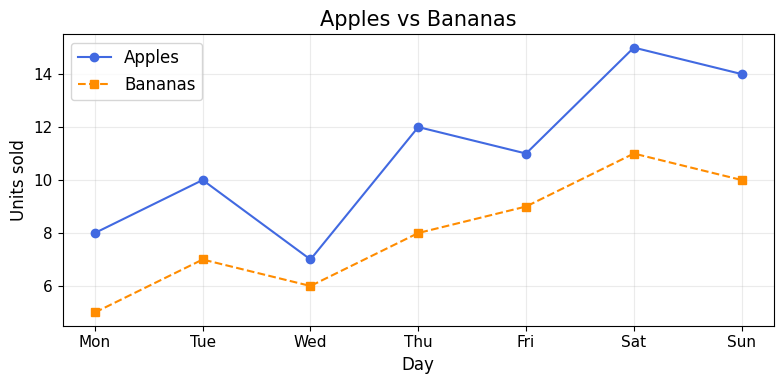

In [15]:
# WORKED EXAMPLE: Apples vs bananas — one figure, two lines
x = shop["day"]
plt.figure(figsize=(8, 4))
plt.plot(x, shop["apples"], color="royalblue", marker="o", label="Apples")
plt.plot(x, shop["bananas"], color="darkorange", marker="s", linestyle="--", label="Bananas")
plt.title("Apples vs Bananas")
plt.xlabel("Day")
plt.ylabel("Units sold")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 02

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 2.1 — Two fruit lines

- **1 · Extract:** `shop["day"]`, `shop["apples"]`, `shop["oranges"]`.
- **2 · Draw:** Two lines on **one chart**.
- **3 · Exact style:** Apples blue solid circles; oranges orange dashed squares.
- **4 · Titles/labels:** Title **Apples and Oranges**; x **Day**; y **Units sold**.
- **5 · Also do this:** Add legend labels **Apples** and **Oranges**.

<details><summary>💡 Show a small hint only if needed</summary>

Call `plt.plot()` twice.

</details>

In [16]:
# Question 2.1 — TWO FRUIT LINES
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 2.2 — Three fruits

- **1 · Extract:** `shop["day"]` and all 3 fruit columns.
- **2 · Draw:** Three lines on one chart.
- **3 · Exact style:** Apples red (`o`); bananas gold (`s`); oranges green (`^`).
- **4 · Titles/labels:** Title **Three Fruit Trends**; x **Day**; y **Units**.
- **5 · Also do this:** Add a three-item legend.

<details><summary>💡 Show a small hint only if needed</summary>

Triangle marker: `marker="^"`.

</details>

In [17]:
# Question 2.2 — THREE FRUITS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 2.3 — Marks by student

- **1 · Extract:** `students["student"]`, `students["math"]`, `students["science"]`.
- **2 · Draw:** Two lines comparing marks for all 10 students.
- **3 · Exact style:** Math navy solid circles; science teal dashed squares.
- **4 · Titles/labels:** Title **Math and Science Scores**; x **Student**; y **Marks / 100**.
- **5 · Also do this:** Rotate student name labels 45° and show a legend.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.xticks(rotation=45)`.

</details>

In [18]:
# Question 2.3 — MARKS BY STUDENT
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 2.4 — Only weekdays

- **1 · Extract:** `shop.iloc[:5]` with `day`, `bananas`, `oranges`.
- **2 · Draw:** Two lines on **Mon–Fri only**.
- **3 · Exact style:** Bananas purple solid; oranges green dotted (`:`).
- **4 · Titles/labels:** Title **Weekday Sales**; x **Day**; y **Units sold**.
- **5 · Also do this:** Use different circle and diamond markers and add legend.

<details><summary>💡 Show a small hint only if needed</summary>

Filter using `.iloc[:5]` first.

</details>

In [19]:
# Question 2.4 — ONLY WEEKDAYS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 2.5 — Compare three subject scores

- **1 · Extract:** `students["student"]` and `math`, `english`, `science` columns.
- **2 · Draw:** Three lines, all 10 students.
- **3 · Exact style:** Math red solid, English blue dashed, Science green dotted.
- **4 · Titles/labels:** Title **Subject Comparison**; x **Student**; y **Marks / 100**.
- **5 · Also do this:** Make linewidth 2 for all, add a legend, rotate names 45°.

<details><summary>💡 Show a small hint only if needed</summary>

Set each line’s `linestyle` separately.

</details>

In [20]:
# Question 2.5 — COMPARE THREE SUBJECT SCORES
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 02 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose multiple lines &amp; line styles and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 03 · 📊 Vertical Bar Chart

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Compare values across distinct categories (days, students, or products).</div>

**Main syntax:** `plt.bar(categories, numbers, color="skyblue")`

**Learn it:** Use `plt.bar(x, height)` for separate categories. Unlike a line chart, bars emphasize category-to-category comparisons. `plt.bar(...)` returns bars you can later label.

## Worked example — run this cell first

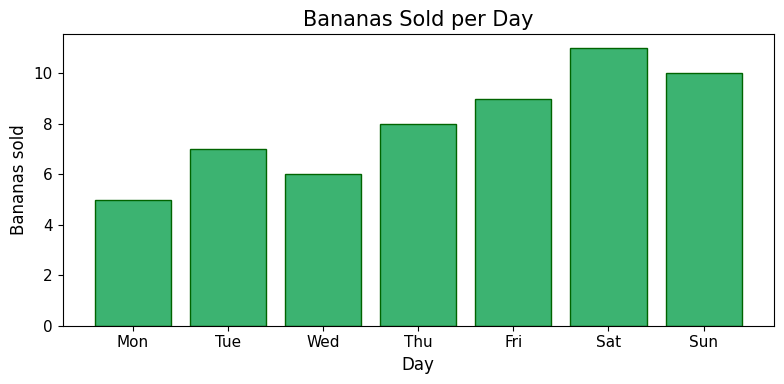

In [21]:
# WORKED EXAMPLE: Bars for daily banana sales
x = shop["day"]
y = shop["bananas"]
plt.figure(figsize=(8, 4))
plt.bar(x, y, color="mediumseagreen", edgecolor="darkgreen")
plt.title("Bananas Sold per Day")
plt.xlabel("Day")
plt.ylabel("Bananas sold")
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 03

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 3.1 — Apples as bars

- **1 · Extract:** `shop["day"]`, `shop["apples"]`.
- **2 · Draw:** 7 **vertical** bars.
- **3 · Exact style:** Sky-blue fill, navy edge.
- **4 · Titles/labels:** Title **Apple Sales by Day**; x **Day**; y **Apples**.
- **5 · Also do this:** Start y-axis at 0 (the usual bar-chart baseline).

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.bar(...)`.

</details>

In [22]:
# Question 3.1 — APPLES AS BARS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 3.2 — Revenue bars

- **1 · Extract:** `shop["day"]`, `shop["revenue"]`.
- **2 · Draw:** 7 vertical bars.
- **3 · Exact style:** Gold fill.
- **4 · Titles/labels:** Title **Revenue by Day**; x **Day**; y **Revenue**.
- **5 · Also do this:** Add horizontal grid **behind** bars (`plt.grid(axis="y", alpha=0.2)`).

<details><summary>💡 Show a small hint only if needed</summary>

Try `plt.grid(axis="y", alpha=0.2)`.

</details>

In [23]:
# Question 3.2 — REVENUE BARS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 3.3 — Math scores

- **1 · Extract:** `students["student"]`, `students["math"]`.
- **2 · Draw:** 10 vertical bars.
- **3 · Exact style:** Slate-blue fill.
- **4 · Titles/labels:** Title **Math Marks**; x **Student**; y **Marks / 100**.
- **5 · Also do this:** Rotate names 45° so none overlap.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.xticks(rotation=45)`.

</details>

In [24]:
# Question 3.3 — MATH SCORES
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 3.4 — Weekday oranges

- **1 · Extract:** `shop.iloc[:5]`, then `day` and `oranges`.
- **2 · Draw:** 5 vertical bars (Mon–Fri).
- **3 · Exact style:** Tomato fill, black edge.
- **4 · Titles/labels:** Title **Weekday Oranges**; x **Day**; y **Oranges**.
- **5 · Also do this:** Use width 0.5 for the bars.

<details><summary>💡 Show a small hint only if needed</summary>

Use `width=0.5` in `plt.bar`.

</details>

In [25]:
# Question 3.4 — WEEKDAY ORANGES
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 3.5 — Top three math scorers

- **1 · Extract:** Sort `students` on `math` descending, take `.head(3)`; x names, y marks.
- **2 · Draw:** 3 vertical bars in **highest-first** order.
- **3 · Exact style:** Teal fill.
- **4 · Titles/labels:** Title **Top 3 in Math**; x **Student**; y **Math marks**.
- **5 · Also do this:** Set the y-axis limit from 0 to 100.

<details><summary>💡 Show a small hint only if needed</summary>

Use `.sort_values("math", ascending=False).head(3)` and `plt.ylim(0, 100)`.

</details>

In [26]:
# Question 3.5 — TOP THREE MATH SCORERS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 03 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose vertical bar chart and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 04 · ↔️ Horizontal Bar Chart

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Compare categories horizontally; useful when labels are names.</div>

**Main syntax:** `plt.barh(names, values, color="coral")`

**Learn it:** `plt.barh(y_labels, widths)` puts labels vertically and bars horizontally. Put the **number** on the horizontal axis and the **category** on the vertical axis.

## Worked example — run this cell first

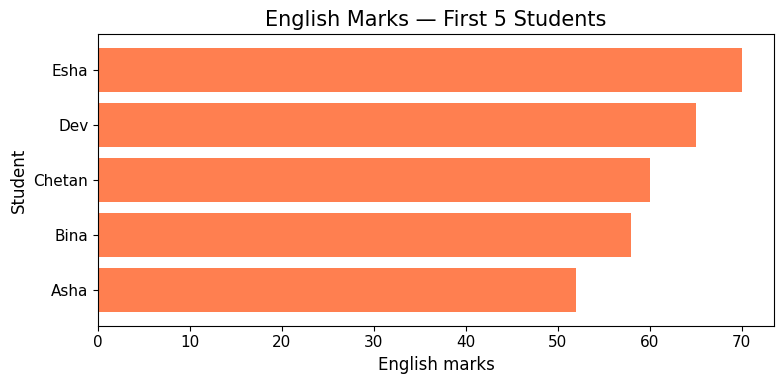

In [27]:
# WORKED EXAMPLE: First five students — horizontal bars
first_five = students.iloc[:5]
plt.figure(figsize=(8, 4))
plt.barh(first_five["student"], first_five["english"], color="coral")
plt.title("English Marks — First 5 Students")
plt.xlabel("English marks")
plt.ylabel("Student")
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 04

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 4.1 — Math marks horizontally

- **1 · Extract:** First 5 rows of `students`; extract `student`, `math`.
- **2 · Draw:** 5 horizontal bars.
- **3 · Exact style:** Cornflower-blue fill.
- **4 · Titles/labels:** Title **Math: First 5 Students**; x **Math marks**; y **Student**.
- **5 · Also do this:** Use `plt.barh()`, not `plt.bar()`.

<details><summary>💡 Show a small hint only if needed</summary>

First extract `subset = students.iloc[:5]`.

</details>

In [28]:
# Question 4.1 — MATH MARKS HORIZONTALLY
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 4.2 — Science marks horizontally

- **1 · Extract:** Last 5 rows of `students`; extract `student`, `science`.
- **2 · Draw:** 5 horizontal bars.
- **3 · Exact style:** Green fill.
- **4 · Titles/labels:** Title **Science: Last 5 Students**; x **Science marks**; y **Student**.
- **5 · Also do this:** Set x-axis limit 0 to 100.

<details><summary>💡 Show a small hint only if needed</summary>

Use `students.iloc[5:]`.

</details>

In [29]:
# Question 4.2 — SCIENCE MARKS HORIZONTALLY
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 4.3 — Daily revenue horizontal

- **1 · Extract:** `shop["day"]` and `shop["revenue"]`.
- **2 · Draw:** 7 horizontal bars.
- **3 · Exact style:** Plum fill.
- **4 · Titles/labels:** Title **Revenue by Day — Horizontal**; x **Revenue**; y **Day**.
- **5 · Also do this:** Add vertical gridlines.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.grid(axis="x", alpha=0.2)`.

</details>

In [30]:
# Question 4.3 — DAILY REVENUE HORIZONTAL
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 4.4 — Three top English students

- **1 · Extract:** Top 3 of `students` sorted by `english` descending; names and English marks.
- **2 · Draw:** 3 horizontal bars.
- **3 · Exact style:** Orange fill.
- **4 · Titles/labels:** Title **Top English Marks**; x **Marks**; y **Student**.
- **5 · Also do this:** Use `plt.gca().invert_yaxis()` to show first (highest) at top.

<details><summary>💡 Show a small hint only if needed</summary>

`plt.gca()` gets the current axes.

</details>

In [31]:
# Question 4.4 — THREE TOP ENGLISH STUDENTS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 4.5 — Three product totals

- **1 · Extract:** Calculate total of `apples`, `bananas`, and `oranges` from `shop`.
- **2 · Draw:** 3 horizontal bars, with product names as categories.
- **3 · Exact style:** Teal fill.
- **4 · Titles/labels:** Title **Weekly Fruit Totals**; x **Units sold**; y **Fruit**.
- **5 · Also do this:** Show product labels **Apples, Bananas, Oranges**.

<details><summary>💡 Show a small hint only if needed</summary>

Try `totals = shop[["apples","bananas","oranges"]].sum()`.

</details>

In [32]:
# Question 4.5 — THREE PRODUCT TOTALS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 04 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose horizontal bar chart and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 05 · 🧱 Grouped Bar Chart

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Compare two or three categories **side by side** within each group.</div>

**Main syntax:** `x = np.arange(len(labels)); plt.bar(x-width/2, first, width=width); plt.bar(x+width/2, second, width=width)`

**Learn it:** Two bar series must be **slightly shifted** left and right. `np.arange(len(labels))` creates numbered bar positions. The same labels are placed using `plt.xticks(positions, labels)`.

## Worked example — run this cell first

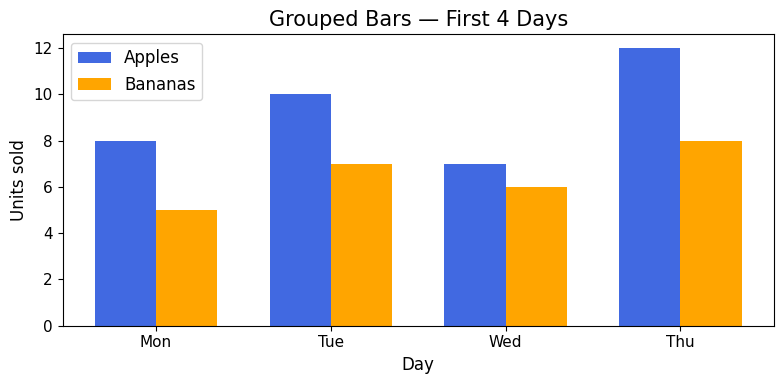

In [33]:
# WORKED EXAMPLE: Grouped apples and bananas — first 4 days
part = shop.iloc[:4]
positions = np.arange(len(part))    # [0, 1, 2, 3]
width = 0.35                         # Width of one bar

plt.figure(figsize=(8, 4))
plt.bar(positions - width / 2, part["apples"], width=width, color="royalblue", label="Apples")
plt.bar(positions + width / 2, part["bananas"], width=width, color="orange", label="Bananas")
plt.xticks(positions, part["day"])
plt.title("Grouped Bars — First 4 Days")
plt.xlabel("Day")
plt.ylabel("Units sold")
plt.legend()
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 05

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 5.1 — Apples and oranges

- **1 · Extract:** First 4 days from `shop`: `day`, `apples`, `oranges`.
- **2 · Draw:** Two side-by-side bars per day.
- **3 · Exact style:** Apples blue; oranges darkorange; width 0.35.
- **4 · Titles/labels:** Title **Apples vs Oranges**; x **Day**; y **Units sold**.
- **5 · Also do this:** Add a 2-item legend.

<details><summary>💡 Show a small hint only if needed</summary>

Use offsets `positions - width/2` and `positions + width/2`.

</details>

In [34]:
# Question 5.1 — APPLES AND ORANGES
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 5.2 — Bananas and oranges

- **1 · Extract:** All 7 days: `day`, `bananas`, `oranges`.
- **2 · Draw:** Two side-by-side bars per day.
- **3 · Exact style:** Bananas gold; oranges green; width 0.35.
- **4 · Titles/labels:** Title **Fruit Pair Comparison**; x **Day**; y **Units**.
- **5 · Also do this:** Use day names as x ticks and add a legend.

<details><summary>💡 Show a small hint only if needed</summary>

Make positions with `np.arange(len(shop))`.

</details>

In [35]:
# Question 5.2 — BANANAS AND ORANGES
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 5.3 — Math versus English

- **1 · Extract:** First 5 students: `student`, `math`, `english`.
- **2 · Draw:** Two grouped bars per student.
- **3 · Exact style:** Math purple; English skyblue.
- **4 · Titles/labels:** Title **Math vs English — First 5**; x **Student**; y **Marks / 100**.
- **5 · Also do this:** Add a legend, no name rotation needed for first five.

<details><summary>💡 Show a small hint only if needed</summary>

Take `students.iloc[:5]`.

</details>

In [36]:
# Question 5.3 — MATH VERSUS ENGLISH
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 5.4 — English versus science

- **1 · Extract:** Last 5 students: `student`, `english`, `science`.
- **2 · Draw:** Two grouped bars per student.
- **3 · Exact style:** English teal; Science coral; width 0.3.
- **4 · Titles/labels:** Title **English vs Science — Last 5**; x **Student**; y **Marks**.
- **5 · Also do this:** Set y-axis from 0 to 100 and add legend.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.ylim(0, 100)`.

</details>

In [37]:
# Question 5.4 — ENGLISH VERSUS SCIENCE
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 5.5 — Three fruits together

- **1 · Extract:** First 3 days: `day`, and 3 fruit columns.
- **2 · Draw:** **Three** narrow bars per day.
- **3 · Exact style:** Apples red; bananas gold; oranges green; width 0.25.
- **4 · Titles/labels:** Title **Three Fruits, Three Days**; x **Day**; y **Units**.
- **5 · Also do this:** Use positions `p-width`, `p`, `p+width` and a 3-item legend.

<details><summary>💡 Show a small hint only if needed</summary>

For three bars, shift by a full width, not half.

</details>

In [38]:
# Question 5.5 — THREE FRUITS TOGETHER
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 05 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose grouped bar chart and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 06 · 🪜 Stacked Bar Chart

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Show a total and what portions make up that total.</div>

**Main syntax:** `plt.bar(x, part1); plt.bar(x, part2, bottom=part1)`

**Learn it:** Stacked bars put one series **on top** of another. `bottom=` tells Matplotlib how high the previous stack already is. Each stack’s total is the sum of its parts.

## Worked example — run this cell first

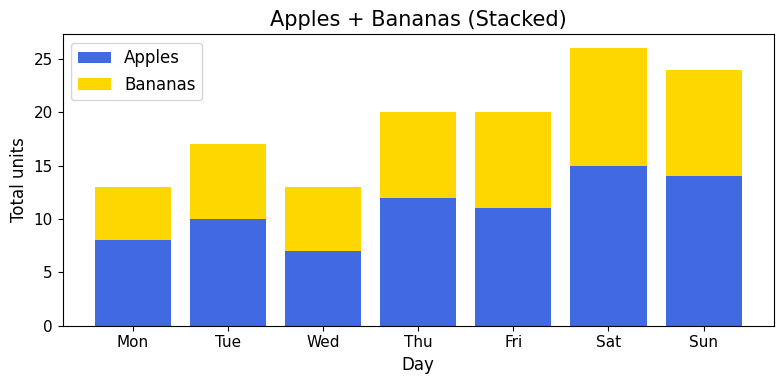

In [39]:
# WORKED EXAMPLE: Stacked apples + bananas, by day
x = shop["day"]
a = shop["apples"]
b = shop["bananas"]
plt.figure(figsize=(8, 4))
plt.bar(x, a, color="royalblue", label="Apples")
plt.bar(x, b, bottom=a, color="gold", label="Bananas")
plt.title("Apples + Bananas (Stacked)")
plt.xlabel("Day")
plt.ylabel("Total units")
plt.legend()
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 06

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 6.1 — Apples and oranges stack

- **1 · Extract:** `shop["day"]`, `shop["apples"]`, `shop["oranges"]`.
- **2 · Draw:** Two stacked bar segments per day.
- **3 · Exact style:** Bottom apples blue; top oranges orange.
- **4 · Titles/labels:** Title **Apples + Oranges**; x **Day**; y **Total units**.
- **5 · Also do this:** Use a legend to name each segment.

<details><summary>💡 Show a small hint only if needed</summary>

For oranges use `bottom=shop["apples"]`.

</details>

In [40]:
# Question 6.1 — APPLES AND ORANGES STACK
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 6.2 — Bananas and oranges stack

- **1 · Extract:** First 5 shop days: `day`, `bananas`, `oranges`.
- **2 · Draw:** Two stacked segments, Mon–Fri.
- **3 · Exact style:** Bottom bananas gold; top oranges green.
- **4 · Titles/labels:** Title **Weekday Fruit Stack**; x **Day**; y **Units**.
- **5 · Also do this:** Show only 5 day labels.

<details><summary>💡 Show a small hint only if needed</summary>

Take `part = shop.iloc[:5]`.

</details>

In [41]:
# Question 6.2 — BANANAS AND ORANGES STACK
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 6.3 — Three-fruit stack

- **1 · Extract:** All 7 days and the `apples`, `bananas`, `oranges` columns.
- **2 · Draw:** Three segments per day.
- **3 · Exact style:** Apples red bottom, bananas yellow middle, oranges green top.
- **4 · Titles/labels:** Title **Total Fruit Composition**; x **Day**; y **Fruit units**.
- **5 · Also do this:** Make three legend labels.

<details><summary>💡 Show a small hint only if needed</summary>

Top bottom is `apples + bananas` (two Series add elementwise).

</details>

In [42]:
# Question 6.3 — THREE-FRUIT STACK
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 6.4 — Stack three subjects

- **1 · Extract:** First 4 students: `student`, `math`, `english`, `science`.
- **2 · Draw:** Three stacked bars per student.
- **3 · Exact style:** Math navy; English teal; Science pink.
- **4 · Titles/labels:** Title **Sum of Subject Marks**; x **Student**; y **Combined marks**.
- **5 · Also do this:** The maximum possible stack is 300, **not 100**.

<details><summary>💡 Show a small hint only if needed</summary>

Middle bottom = math; top bottom = math + english.

</details>

In [43]:
# Question 6.4 — STACK THREE SUBJECTS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 6.5 — Stack after sorting

- **1 · Extract:** Sort `shop` by `apples` ascending; extract `day`, `apples`, `bananas`.
- **2 · Draw:** Two segments per day in sorted-day order.
- **3 · Exact style:** Bottom apples purple; top bananas orange.
- **4 · Titles/labels:** Title **Sorted Stacked Fruit Sales**; x **Day**; y **Units**.
- **5 · Also do this:** Add a legend and keep the day order generated by sorting.

<details><summary>💡 Show a small hint only if needed</summary>

Try `.sort_values("apples")`.

</details>

In [44]:
# Question 6.5 — STACK AFTER SORTING
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 06 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose stacked bar chart and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 07 · 🔵 Scatter Plot

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Explore the relationship between TWO numeric variables.</div>

**Main syntax:** `plt.scatter(x, y, color="teal", s=80, alpha=0.8)`

**Learn it:** Scatter plots draw **individual dots without connecting lines**. `s` controls dot area (size) and `alpha` controls transparency (0 transparent, 1 solid).

## Worked example — run this cell first

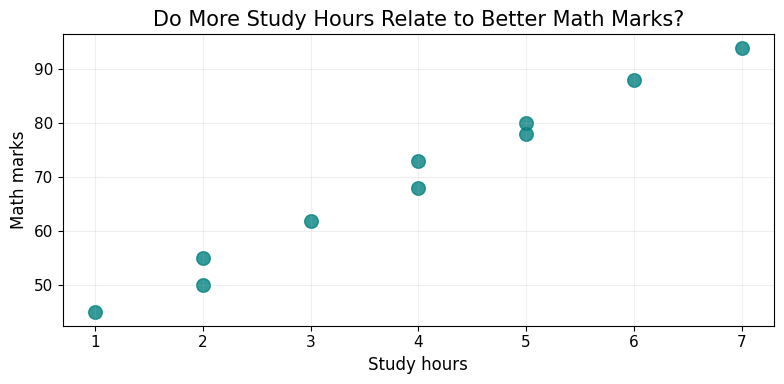

In [45]:
# WORKED EXAMPLE: Study hours vs math marks
x = students["hours"]
y = students["math"]
plt.figure(figsize=(8, 4))
plt.scatter(x, y, color="teal", s=95, alpha=0.8)
plt.title("Do More Study Hours Relate to Better Math Marks?")
plt.xlabel("Study hours")
plt.ylabel("Math marks")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 07

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 7.1 — Hours and science

- **1 · Extract:** `students["hours"]` → x, `students["science"]` → y.
- **2 · Draw:** A scatter plot with 10 dots.
- **3 · Exact style:** Royal-blue dots; size (`s`) 70.
- **4 · Titles/labels:** Title **Hours vs Science**; x **Study hours**; y **Science marks**.
- **5 · Also do this:** Do not connect the dots.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.scatter`.

</details>

In [46]:
# Question 7.1 — HOURS AND SCIENCE
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 7.2 — Hours and English

- **1 · Extract:** `students["hours"]`, `students["english"]`.
- **2 · Draw:** A scatter plot.
- **3 · Exact style:** Orange dots; `s=110`; `alpha=0.6`.
- **4 · Titles/labels:** Title **Hours vs English**; x **Hours**; y **English marks**.
- **5 · Also do this:** Add a light grid.

<details><summary>💡 Show a small hint only if needed</summary>

Use `alpha=0.6` for transparency.

</details>

In [47]:
# Question 7.2 — HOURS AND ENGLISH
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 7.3 — Math vs science

- **1 · Extract:** `students["math"]` → x, `students["science"]` → y.
- **2 · Draw:** A scatter plot.
- **3 · Exact style:** Darkgreen dots; `s=80`.
- **4 · Titles/labels:** Title **Math vs Science**; x **Math marks**; y **Science marks**.
- **5 · Also do this:** Set BOTH axes limits from 0 to 100.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.xlim(0,100)` and `plt.ylim(0,100)`.

</details>

In [48]:
# Question 7.3 — MATH VS SCIENCE
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 7.4 — Customers vs revenue

- **1 · Extract:** `shop["customers"]` → x, `shop["revenue"]` → y.
- **2 · Draw:** 7-point scatter plot.
- **3 · Exact style:** Tomato dots; `s=100`.
- **4 · Titles/labels:** Title **Customers vs Revenue**; x **Customers**; y **Revenue**.
- **5 · Also do this:** Use a light horizontal grid.

<details><summary>💡 Show a small hint only if needed</summary>

Each row in `shop` contributes one dot.

</details>

In [49]:
# Question 7.4 — CUSTOMERS VS REVENUE
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 7.5 — Two scatter groups

- **1 · Extract:** First 5 students and last 5 students; `hours` and `math`.
- **2 · Draw:** Two differently colored sets of dots on ONE chart.
- **3 · Exact style:** First 5 blue dots; last 5 coral dots; `s=90`.
- **4 · Titles/labels:** Title **Study Hours by Student Group**; x **Hours**; y **Math marks**.
- **5 · Also do this:** Legend labels **First five** and **Last five**.

<details><summary>💡 Show a small hint only if needed</summary>

Call `plt.scatter()` twice and add `label=`.

</details>

In [50]:
# Question 7.5 — TWO SCATTER GROUPS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 07 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose scatter plot and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 08 · 📦 Histogram

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Count how many numeric values fall within number ranges (bins).</div>

**Main syntax:** `plt.hist(numbers, bins=5, color="skyblue", edgecolor="black")`

**Learn it:** A histogram groups **numeric values into ranges**. It is NOT a bar chart of student names. `bins=5` asks for five intervals. The y-axis usually shows **frequency (count)**.

## Worked example — run this cell first

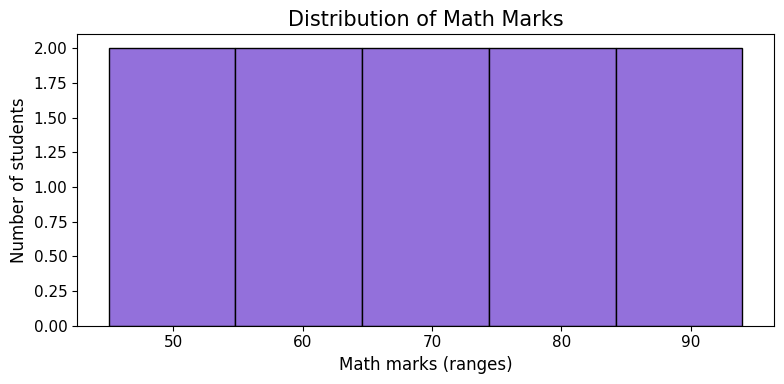

In [51]:
# WORKED EXAMPLE: Distribution of math scores
marks = students["math"]            # Ten numeric observations
plt.figure(figsize=(8, 4))
plt.hist(marks, bins=5, color="mediumpurple", edgecolor="black")
plt.title("Distribution of Math Marks")
plt.xlabel("Math marks (ranges)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 08

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 8.1 — English score distribution

- **1 · Extract:** `students["english"]`.
- **2 · Draw:** One histogram of 10 score values.
- **3 · Exact style:** 4 bins; skyblue bars; black outlines.
- **4 · Titles/labels:** Title **English Marks Distribution**; x **English mark ranges**; y **Student count**.
- **5 · Also do this:** Notice how observations get grouped into ranges.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.hist(..., bins=4)`.

</details>

In [52]:
# Question 8.1 — ENGLISH SCORE DISTRIBUTION
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 8.2 — Science score distribution

- **1 · Extract:** `students["science"]`.
- **2 · Draw:** One histogram.
- **3 · Exact style:** 5 bins; lightgreen fill; black outlines.
- **4 · Titles/labels:** Title **Science Marks Distribution**; x **Science mark ranges**; y **Frequency**.
- **5 · Also do this:** Add horizontal grid lines.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.grid(axis="y", alpha=0.2)`.

</details>

In [53]:
# Question 8.2 — SCIENCE SCORE DISTRIBUTION
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 8.3 — Hours distribution

- **1 · Extract:** `students["hours"]`.
- **2 · Draw:** One histogram of study hours.
- **3 · Exact style:** 6 bins; coral fill; black outlines.
- **4 · Titles/labels:** Title **Study Hours Distribution**; x **Hours ranges**; y **Number of students**.
- **5 · Also do this:** Keep histogram bars touching as normal.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.hist` rather than `plt.bar`.

</details>

In [54]:
# Question 8.3 — HOURS DISTRIBUTION
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 8.4 — Daily customer distribution

- **1 · Extract:** `shop["customers"]`.
- **2 · Draw:** A histogram of 7 daily customer counts.
- **3 · Exact style:** 3 bins; teal fill; navy outline.
- **4 · Titles/labels:** Title **Daily Customer Counts**; x **Customer-count ranges**; y **Number of days**.
- **5 · Also do this:** Explain in a comment that the y-axis counts **days**.

<details><summary>💡 Show a small hint only if needed</summary>

Frequency means number of observations in a bin.

</details>

In [55]:
# Question 8.4 — DAILY CUSTOMER DISTRIBUTION
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 8.5 — Compare two histograms

- **1 · Extract:** `students["math"]` and `students["english"]`.
- **2 · Draw:** Two overlapping histograms on **the same axes**.
- **3 · Exact style:** Both use bins `range(40, 101, 10)`; math blue, English orange; alpha 0.5.
- **4 · Titles/labels:** Title **Math and English Distributions**; x **Marks**; y **Frequency**.
- **5 · Also do this:** Add a legend and use identical bin edges.

<details><summary>💡 Show a small hint only if needed</summary>

Call `plt.hist` twice with the same `bins=range(40, 101, 10)`.

</details>

In [56]:
# Question 8.5 — COMPARE TWO HISTOGRAMS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 08 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose histogram and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 09 · 🥧 Pie Chart

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Show how parts share ONE whole, especially percentages.</div>

**Main syntax:** `plt.pie(values, labels=names, autopct="%1.1f%%", startangle=90)`

**Learn it:** Pie charts need **category totals** rather than day labels. Sum the sales for each fruit first; then make one slice per fruit. `autopct` displays the percentages.

## Worked example — run this cell first

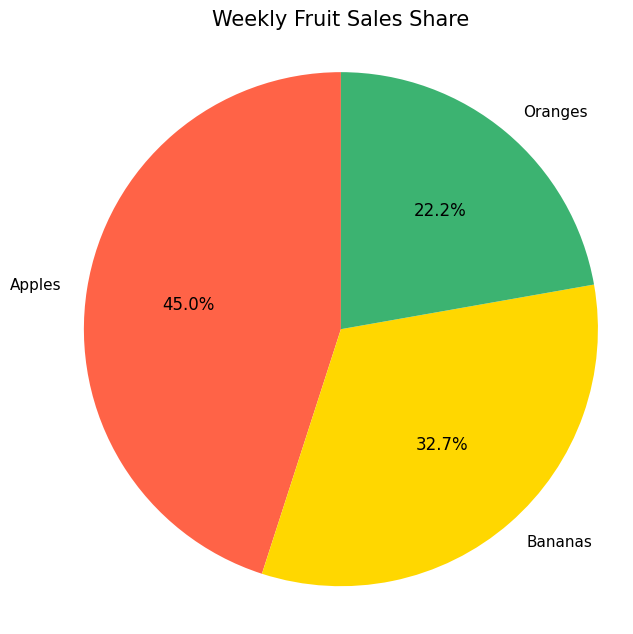

In [57]:
# WORKED EXAMPLE: What share of all fruit sold was each fruit?
totals = shop[["apples", "bananas", "oranges"]].sum()
labels = ["Apples", "Bananas", "Oranges"]
values = totals.to_numpy()   # 3 total values

plt.figure(figsize=(6.5, 6.5))
plt.pie(values, labels=labels, colors=["tomato", "gold", "mediumseagreen"],
        autopct="%1.1f%%", startangle=90)
plt.title("Weekly Fruit Sales Share")
plt.axis("equal")
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 09

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 9.1 — Fruit totals pie, new colors

- **1 · Extract:** Sum all 7 rows of `apples`, `bananas`, and `oranges`.
- **2 · Draw:** One 3-slice pie chart.
- **3 · Exact style:** Colors `red`, `orange`, `green`; percentages to 1 decimal.
- **4 · Titles/labels:** Title **Fruit Sales Percentages**; labels **Apples**, **Bananas**, **Oranges**.
- **5 · Also do this:** Rotate start to 180°.

<details><summary>💡 Show a small hint only if needed</summary>

Use `startangle=180`.

</details>

In [58]:
# Question 9.1 — FRUIT TOTALS PIE, NEW COLORS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 9.2 — First three days share

- **1 · Extract:** `shop.iloc[:3]`: sum the three fruit columns.
- **2 · Draw:** One 3-slice pie chart.
- **3 · Exact style:** Colors `lightcoral`, `khaki`, `lightgreen`.
- **4 · Titles/labels:** Title **Mon–Wed Fruit Share**; fruit labels.
- **5 · Also do this:** Display percentages; start angle 90°.

<details><summary>💡 Show a small hint only if needed</summary>

Sum the columns AFTER selecting the first 3 days.

</details>

In [59]:
# Question 9.2 — FIRST THREE DAYS SHARE
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 9.3 — Weekend sales share

- **1 · Extract:** `shop.iloc[5:]` to get Sat–Sun, then sum the three fruit columns.
- **2 · Draw:** One 3-slice pie chart.
- **3 · Exact style:** Colors `tomato`, `gold`, `teal`.
- **4 · Titles/labels:** Title **Weekend Fruit Share**; fruit labels.
- **5 · Also do this:** Show percentages.

<details><summary>💡 Show a small hint only if needed</summary>

Weekend is rows at positions 5 and 6.

</details>

In [60]:
# Question 9.3 — WEEKEND SALES SHARE
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 9.4 — Two-slice fruit comparison

- **1 · Extract:** Weekly **total apples** and weekly **total bananas** only.
- **2 · Draw:** One 2-slice pie chart.
- **3 · Exact style:** Apples skyblue, bananas plum.
- **4 · Titles/labels:** Title **Apples vs Bananas Share**; labels **Apples**, **Bananas**.
- **5 · Also do this:** Use percentages with zero digits after decimal (`%1.0f%%`).

<details><summary>💡 Show a small hint only if needed</summary>

Values list can be `[shop["apples"].sum(), shop["bananas"].sum()]`.

</details>

In [61]:
# Question 9.4 — TWO-SLICE FRUIT COMPARISON
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 9.5 — Average subject marks share

- **1 · Extract:** Calculate average `math`, `english`, `science` marks across all 10 students.
- **2 · Draw:** One 3-slice pie for the **share of the sum of three subject averages**.
- **3 · Exact style:** Math purple, English skyblue, Science green.
- **4 · Titles/labels:** Title **Share of Subject Averages**; labels **Math**, **English**, **Science**.
- **5 · Also do this:** Display percentages and clarify in a comment that this is a **practice visualization**, not student proportions.

<details><summary>💡 Show a small hint only if needed</summary>

Use `students[["math","english","science"]].mean()`.

</details>

In [62]:
# Question 9.5 — AVERAGE SUBJECT MARKS SHARE
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 09 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose pie chart and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 10 · 📐 Box Plot

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Summarize a numeric spread: middle, quartiles, and possible outliers.</div>

**Main syntax:** `plt.boxplot([list1, list2]); plt.xticks([1, 2], ["A", "B"])`

**Learn it:** A box plot summarizes many numbers in one mark: line in the box = median; box = middle half; whiskers show a larger typical range. Compare several numeric columns by passing a LIST of series.

## Worked example — run this cell first

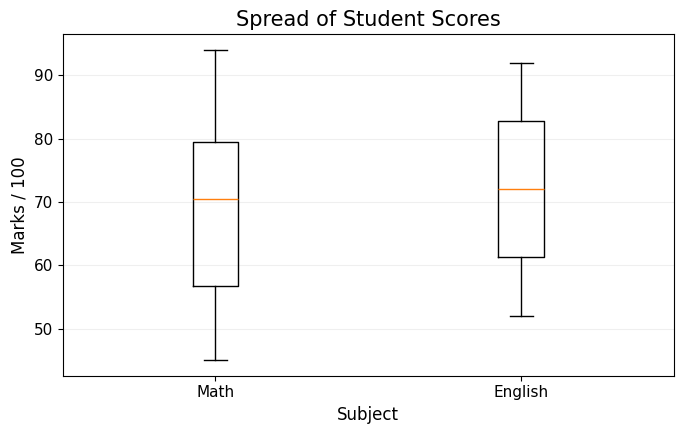

In [63]:
# WORKED EXAMPLE: Compare the spread of Math and English marks
math_marks = students["math"]
english_marks = students["english"]

plt.figure(figsize=(7, 4.5))
plt.boxplot([math_marks, english_marks])
plt.xticks([1, 2], ["Math", "English"])
plt.title("Spread of Student Scores")
plt.xlabel("Subject")
plt.ylabel("Marks / 100")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 10

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 10.1 — Science box plot

- **1 · Extract:** `students["science"]`.
- **2 · Draw:** One box plot.
- **3 · Exact style:** Default Matplotlib box lines.
- **4 · Titles/labels:** Title **Science Marks Spread**; x **Subject**; y **Marks / 100**.
- **5 · Also do this:** Set the single x tick label to **Science**.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.xticks([1], ["Science"])`.

</details>

In [64]:
# Question 10.1 — SCIENCE BOX PLOT
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 10.2 — Three subject boxes

- **1 · Extract:** `students["math"]`, `english`, `science`.
- **2 · Draw:** Three boxes side by side.
- **3 · Exact style:** Default box styling.
- **4 · Titles/labels:** Title **All Subject Spreads**; x **Subject**; y **Marks**.
- **5 · Also do this:** Label x ticks Math, English, Science.

<details><summary>💡 Show a small hint only if needed</summary>

Pass `[math, english, science]` to `plt.boxplot`.

</details>

In [65]:
# Question 10.2 — THREE SUBJECT BOXES
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 10.3 — First half vs last half

- **1 · Extract:** `students.iloc[:5]["math"]` and `students.iloc[5:]["math"]`.
- **2 · Draw:** Two math-score boxes for two groups.
- **3 · Exact style:** Default styling.
- **4 · Titles/labels:** Title **Math: First Five vs Last Five**; x **Group**; y **Math marks**.
- **5 · Also do this:** Label boxes **First 5** and **Last 5**.

<details><summary>💡 Show a small hint only if needed</summary>

Each group is a series of five marks.

</details>

In [66]:
# Question 10.3 — FIRST HALF VS LAST HALF
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 10.4 — Fruit units distribution

- **1 · Extract:** `shop["apples"]`, `shop["bananas"]`, `shop["oranges"]`.
- **2 · Draw:** Three boxes (each summarizes 7 days).
- **3 · Exact style:** Default styling.
- **4 · Titles/labels:** Title **Daily Fruit Sales Spread**; x **Fruit**; y **Units / day**.
- **5 · Also do this:** Label x ticks Apples, Bananas, Oranges.

<details><summary>💡 Show a small hint only if needed</summary>

Each fruit column is a list of 7 numbers.

</details>

In [67]:
# Question 10.4 — FRUIT UNITS DISTRIBUTION
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 10.5 — Two boxes with horizontal grid

- **1 · Extract:** `students["english"]` and `students["science"]`.
- **2 · Draw:** Two boxes side by side.
- **3 · Exact style:** Use `showmeans=True` to show average marks.
- **4 · Titles/labels:** Title **English vs Science Spread**; x **Subject**; y **Marks**.
- **5 · Also do this:** Set y-axis to 0–100 and add y grid.

<details><summary>💡 Show a small hint only if needed</summary>

`plt.boxplot([...], showmeans=True)` puts a mean marker on the chart.

</details>

In [68]:
# Question 10.5 — TWO BOXES WITH HORIZONTAL GRID
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 10 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose box plot and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 11 · 🌊 Area Chart (fill_between)

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Emphasize the amount under a line over an ordered axis.</div>

**Main syntax:** `plt.fill_between(x_positions, y, color="skyblue", alpha=0.4)`

**Learn it:** Draw a normal line, then shade down to the baseline with `plt.fill_between`. For day names, it is easiest to use numeric x positions and replace their tick labels with day names.

## Worked example — run this cell first

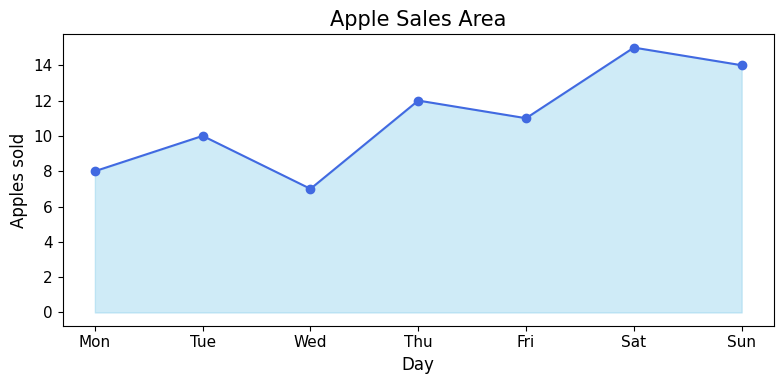

In [69]:
# WORKED EXAMPLE: Filled apple-sales area
x = np.arange(len(shop))         # 0...6, one number per day
y = shop["apples"]
plt.figure(figsize=(8, 4))
plt.plot(x, y, color="royalblue", marker="o")
plt.fill_between(x, y, color="skyblue", alpha=0.4)
plt.xticks(x, shop["day"])
plt.title("Apple Sales Area")
plt.xlabel("Day")
plt.ylabel("Apples sold")
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 11

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 11.1 — Banana filled area

- **1 · Extract:** `shop["day"]`, `shop["bananas"]`; make x positions with `np.arange`.
- **2 · Draw:** A banana line plus filled area.
- **3 · Exact style:** Darkgreen line; lightgreen fill, alpha 0.4.
- **4 · Titles/labels:** Title **Banana Sales Area**; x **Day**; y **Bananas**.
- **5 · Also do this:** Replace x positions with day tick labels.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.xticks(x, shop["day"])`.

</details>

In [70]:
# Question 11.1 — BANANA FILLED AREA
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 11.2 — Revenue filled area

- **1 · Extract:** `shop["day"]`, `shop["revenue"]`.
- **2 · Draw:** A revenue line plus filled area.
- **3 · Exact style:** Darkorange line; gold fill, alpha 0.3.
- **4 · Titles/labels:** Title **Revenue Area**; x **Day**; y **Revenue**.
- **5 · Also do this:** Add y-axis grid.

<details><summary>💡 Show a small hint only if needed</summary>

Use `np.arange(len(shop))` for numeric x.

</details>

In [71]:
# Question 11.2 — REVENUE FILLED AREA
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 11.3 — First four-day orange area

- **1 · Extract:** `shop.iloc[:4]`, then `day` and `oranges`.
- **2 · Draw:** One filled area with 4 points.
- **3 · Exact style:** Tomato line and salmon fill, alpha 0.45.
- **4 · Titles/labels:** Title **Orange Sales: First 4 Days**; x **Day**; y **Oranges**.
- **5 · Also do this:** Add circle markers to the line.

<details><summary>💡 Show a small hint only if needed</summary>

Match positions to the subset length.

</details>

In [72]:
# Question 11.3 — FIRST FOUR-DAY ORANGE AREA
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 11.4 — Customer count area

- **1 · Extract:** All `day` and `customers` values.
- **2 · Draw:** One filled area.
- **3 · Exact style:** Navy line; lightsteelblue fill, alpha 0.5.
- **4 · Titles/labels:** Title **Customer Activity Area**; x **Day**; y **Customers**.
- **5 · Also do this:** Show small square markers on the line.

<details><summary>💡 Show a small hint only if needed</summary>

Use `marker="s"`.

</details>

In [73]:
# Question 11.4 — CUSTOMER COUNT AREA
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 11.5 — Total-fruit area

- **1 · Extract:** All days and `fruit_total`.
- **2 · Draw:** One filled area with total fruit units.
- **3 · Exact style:** Purple line; plum fill, alpha 0.35.
- **4 · Titles/labels:** Title **Combined Fruit Units Area**; x **Day**; y **Total fruit units**.
- **5 · Also do this:** Set y limit starting at 0 and show y grid.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.ylim(bottom=0)`.

</details>

In [74]:
# Question 11.5 — TOTAL-FRUIT AREA
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 11 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose area chart (fill_between) and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 12 · 🖼️ Subplots (Multiple Charts in One Figure)

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Put separate plots together without mixing their axes.</div>

**Main syntax:** `fig, axes = plt.subplots(1, 2); axes[0].plot(...); axes[1].bar(...)`

**Learn it:** `fig` is the whole figure. `axes[0]` means the **first small plot**, `axes[1]` the **second**. Use `axes[i].set_title`, `set_xlabel`, `set_ylabel` rather than global `plt.title` to label each panel.

## Worked example — run this cell first

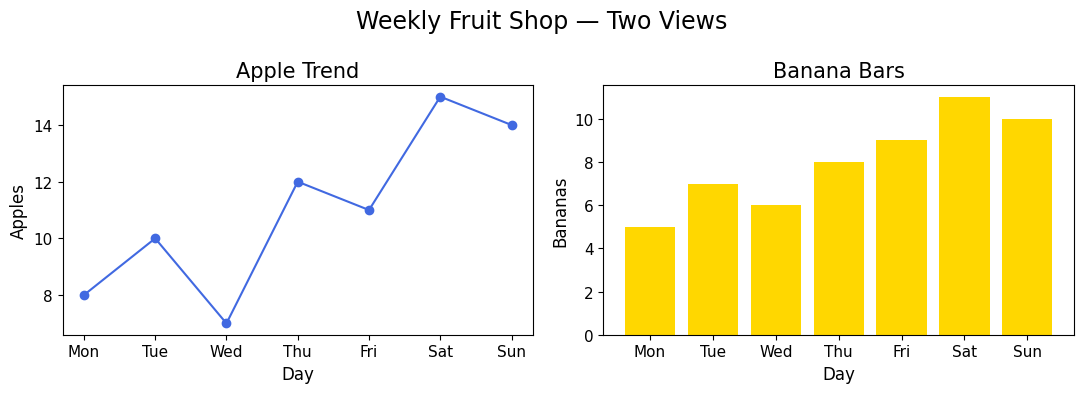

In [75]:
# WORKED EXAMPLE: Line on the left, bars on the right
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(shop["day"], shop["apples"], color="royalblue", marker="o")
axes[0].set_title("Apple Trend")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Apples")

axes[1].bar(shop["day"], shop["bananas"], color="gold")
axes[1].set_title("Banana Bars")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Bananas")

fig.suptitle("Weekly Fruit Shop — Two Views", fontsize=17)
fig.tight_layout()
plt.show()

## Your 5 practice questions — Plot 12

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 12.1 — Line + bar side by side

- **1 · Extract:** `shop`: `day`, `oranges`, `apples`.
- **2 · Draw:** Make `plt.subplots(1, 2)`; left orange line, right apple bars.
- **3 · Exact style:** Left line darkorange; right bars skyblue.
- **4 · Titles/labels:** Panel titles **Orange Trend**, **Apple Bars**; label both axes.
- **5 · Also do this:** Use `figsize=(11, 4)`.

<details><summary>💡 Show a small hint only if needed</summary>

Use `axes[0]` and `axes[1]`.

</details>

In [76]:
# Question 12.1 — LINE + BAR SIDE BY SIDE
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 12.2 — Two mark histograms

- **1 · Extract:** `students["math"]` and `students["science"]`.
- **2 · Draw:** Make 1 row and 2 columns; a histogram in each.
- **3 · Exact style:** Math mediumpurple, Science mediumseagreen; bins 5 both.
- **4 · Titles/labels:** Titles **Math Distribution**, **Science Distribution**; x **Marks**; y **Frequency**.
- **5 · Also do this:** Use dark edges on both histograms.

<details><summary>💡 Show a small hint only if needed</summary>

Use `axes[0].hist(...)`, `axes[1].hist(...)`.

</details>

In [77]:
# Question 12.2 — TWO MARK HISTOGRAMS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 12.3 — Two line charts vertically

- **1 · Extract:** `shop["day"]` with `customers` and `revenue`.
- **2 · Draw:** Make `plt.subplots(2, 1)`; customer line on top; revenue line below.
- **3 · Exact style:** Top teal line; bottom coral line.
- **4 · Titles/labels:** Titles **Customers**, **Revenue**; x **Day** on both; own y labels.
- **5 · Also do this:** Use `figsize=(9, 7)`.

<details><summary>💡 Show a small hint only if needed</summary>

With `2,1`, axes[0] is top and axes[1] bottom.

</details>

In [78]:
# Question 12.3 — TWO LINE CHARTS VERTICALLY
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 12.4 — Student scatter + bar

- **1 · Extract:** `students["hours"]`, `math` and first 5 `student`, `english`.
- **2 · Draw:** Make 1x2; left scatter hours vs math; right bars first 5 English scores.
- **3 · Exact style:** Scatter purple, bars orange.
- **4 · Titles/labels:** Titles **Hours vs Math**, **English: First 5**; appropriate axis labels.
- **5 · Also do this:** Set figure size to (11, 4).

<details><summary>💡 Show a small hint only if needed</summary>

Use `axes[0].scatter` and `axes[1].bar`.

</details>

In [79]:
# Question 12.4 — STUDENT SCATTER + BAR
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 12.5 — Four small fruit plots

- **1 · Extract:** `shop["day"]`, 3 fruit columns and `customers`.
- **2 · Draw:** Make a **2x2** grid: apples line, bananas bars, oranges line, customers bars.
- **3 · Exact style:** Apples blue, bananas gold, oranges green, customers purple.
- **4 · Titles/labels:** Titles each mini-chart and give each y-axis a meaningful label.
- **5 · Also do this:** Use `axes[0,0]`, `axes[0,1]`, `axes[1,0]`, `axes[1,1]`.

<details><summary>💡 Show a small hint only if needed</summary>

`fig, axes = plt.subplots(2,2, figsize=(12,7))`.

</details>

In [80]:
# Question 12.5 — FOUR SMALL FRUIT PLOTS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 12 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose subplots (multiple charts in one figure) and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 13 · 🟩 Heatmap (imshow)

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Show a small table of numbers as colors.</div>

**Main syntax:** `plt.imshow(matrix, cmap="YlGnBu", aspect="auto"); plt.colorbar()`

**Learn it:** A heatmap requires a 2-D table or matrix of numeric values. `df[[...]].to_numpy()` creates one. `cmap` chooses a color palette. The colorbar explains how colors correspond to values.

## Worked example — run this cell first

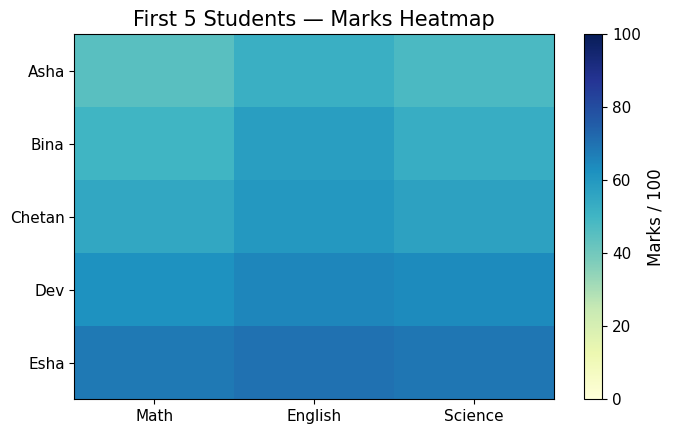

In [81]:
# WORKED EXAMPLE: First 5 students and their three subject marks
part = students.iloc[:5]
subjects = ["math", "english", "science"]
matrix = part[subjects].to_numpy()  # 5 rows x 3 columns

plt.figure(figsize=(7, 4.5))
plt.imshow(matrix, cmap="YlGnBu", aspect="auto", vmin=0, vmax=100)
plt.xticks(range(3), ["Math", "English", "Science"])
plt.yticks(range(len(part)), part["student"])
plt.title("First 5 Students — Marks Heatmap")
plt.colorbar(label="Marks / 100")
plt.tight_layout()
plt.show()

## Your 5 practice questions — Plot 13

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 13.1 — Last five students

- **1 · Extract:** `students.iloc[5:]`; select `math`, `english`, `science` as a 2-D array.
- **2 · Draw:** A **5 × 3** heatmap.
- **3 · Exact style:** Colormap `Blues`, vmin=0, vmax=100.
- **4 · Titles/labels:** Title **Last 5 Marks Heatmap**; x labels Math/English/Science; y labels student names.
- **5 · Also do this:** Add a colorbar named **Marks**.

<details><summary>💡 Show a small hint only if needed</summary>

Use `.to_numpy()` on the 3 columns.

</details>

In [82]:
# Question 13.1 — LAST FIVE STUDENTS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 13.2 — Two subject heatmap

- **1 · Extract:** First 5 students; select `math` and `science`.
- **2 · Draw:** A **5 × 2** heatmap.
- **3 · Exact style:** Colormap `Greens`, vmin=0, vmax=100.
- **4 · Titles/labels:** Title **Math and Science Heatmap**; x labels Math/Science; y labels names.
- **5 · Also do this:** Add a colorbar.

<details><summary>💡 Show a small hint only if needed</summary>

Only two columns means `plt.xticks(range(2), ...)`.

</details>

In [83]:
# Question 13.2 — TWO SUBJECT HEATMAP
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 13.3 — All students heatmap

- **1 · Extract:** All 10 students and all 3 subjects.
- **2 · Draw:** A **10 × 3** heatmap.
- **3 · Exact style:** Colormap `viridis`, vmin=0, vmax=100.
- **4 · Titles/labels:** Title **All Students Heatmap**; x subjects; y students.
- **5 · Also do this:** Use figure size (8, 6) and colorbar.

<details><summary>💡 Show a small hint only if needed</summary>

Use `students[["math","english","science"]].to_numpy()`.

</details>

In [84]:
# Question 13.3 — ALL STUDENTS HEATMAP
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 13.4 — Weekly fruit heatmap

- **1 · Extract:** `shop`: numeric columns `apples`, `bananas`, `oranges` (7 × 3).
- **2 · Draw:** A **7 × 3** heatmap.
- **3 · Exact style:** Colormap `Oranges`.
- **4 · Titles/labels:** Title **Fruit Sales Heatmap**; x labels Apples/Bananas/Oranges; y labels Mon–Sun.
- **5 · Also do this:** Add colorbar label **Fruit units**.

<details><summary>💡 Show a small hint only if needed</summary>

Use the 3 product columns as a matrix.

</details>

In [85]:
# Question 13.4 — WEEKLY FRUIT HEATMAP
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 13.5 — Heatmap with values

- **1 · Extract:** First 3 students and 3 subjects (`math`, `english`, `science`).
- **2 · Draw:** A **3 × 3** heatmap.
- **3 · Exact style:** Colormap `YlGnBu`, vmin=0, vmax=100.
- **4 · Titles/labels:** Title **Three Students with Scores**; x subject names; y student names.
- **5 · Also do this:** Write each numeric mark in its colored square using `plt.text`.

<details><summary>💡 Show a small hint only if needed</summary>

Use nested `for r in range(3)` and `for c in range(3)`: `plt.text(c, r, matrix[r,c], ha="center", va="center")`.

</details>

In [86]:
# Question 13.5 — HEATMAP WITH VALUES
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 13 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose heatmap (imshow) and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# Plot 14 · 🖌️ Chart Styling, Annotation & Saving

<div style="font-size:19px;color:#215776;line-height:1.65;margin:10px 0 8px 0;"><strong>When to use:</strong> Make charts presentation-ready with ticks, labels, values, and image files.</div>

**Main syntax:** `plt.grid(...); plt.annotate(...); plt.savefig("plot.png", dpi=150)`

**Learn it:** Your chart already works: now make it easy to read. Use `plt.grid()` for guides, `plt.xticks()` for names, `plt.text()` or `plt.annotate()` for callouts, and `plt.savefig()` to export a plot. **Save before `plt.show()`** for consistent results.

## Worked example — run this cell first

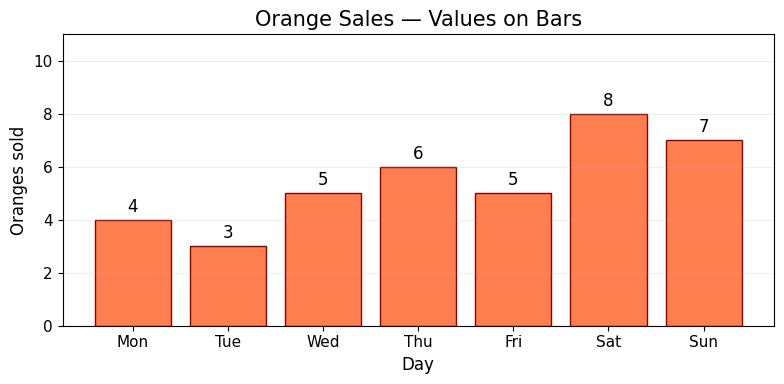

In [87]:
# WORKED EXAMPLE: Label the height of each orange bar
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(shop["day"], shop["oranges"], color="coral", edgecolor="darkred")
ax.bar_label(bars, padding=3)             # Add value above each bar
ax.set_title("Orange Sales — Values on Bars")
ax.set_xlabel("Day")
ax.set_ylabel("Oranges sold")
ax.set_ylim(0, max(shop["oranges"]) + 3) # Leave room for labels
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## Your 5 practice questions — Plot 14

You have seen the example. **Now create five NEW charts yourself.** Choose each question’s x and y (or categories and values) as instructed. The code cell under each question is intentionally empty.

### Question 14.1 — Label bar values

- **1 · Extract:** `shop["day"]` and `shop["apples"]`.
- **2 · Draw:** A 7-bar chart.
- **3 · Exact style:** Skyblue bars, navy edges.
- **4 · Titles/labels:** Title **Apples with Values**; x **Day**; y **Apples sold**.
- **5 · Also do this:** Write each bar value above it using `ax.bar_label`.

<details><summary>💡 Show a small hint only if needed</summary>

Use `fig, ax = plt.subplots(); bars = ax.bar(...); ax.bar_label(bars)`.

</details>

In [88]:
# Question 14.1 — LABEL BAR VALUES
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 14.2 — Rotate long x labels

- **1 · Extract:** All `student` names and `science` marks.
- **2 · Draw:** A vertical bar chart.
- **3 · Exact style:** Mediumpurple bars.
- **4 · Titles/labels:** Title **Science Marks by Student**; x **Student**; y **Science marks**.
- **5 · Also do this:** Rotate names 45°, use `plt.tight_layout()` so labels are visible.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.xticks(rotation=45)`.

</details>

In [89]:
# Question 14.2 — ROTATE LONG X LABELS
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 14.3 — Legend and dashed grid

- **1 · Extract:** `shop["day"]` and `shop["customers"]`.
- **2 · Draw:** A line chart.
- **3 · Exact style:** Teal solid line with circles.
- **4 · Titles/labels:** Title **Customers — Styled Plot**; x **Day**; y **Customers**.
- **5 · Also do this:** Show legend **Customers** and dashed y-grid (`linestyle="--"`).

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.grid(axis="y", linestyle="--", alpha=0.3)`.

</details>

In [90]:
# Question 14.3 — LEGEND AND DASHED GRID
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 14.4 — Highlight the maximum point

- **1 · Extract:** `shop["day"]` and `shop["revenue"]`.
- **2 · Draw:** A line chart with an annotation at the **largest revenue** point.
- **3 · Exact style:** Navy line; orange marker or annotation arrow.
- **4 · Titles/labels:** Title **Peak Revenue Day**; x **Day**; y **Revenue**.
- **5 · Also do this:** Point to the highest point and label it **Peak: 400**.

<details><summary>💡 Show a small hint only if needed</summary>

Find row with `.idxmax()`; use `plt.annotate("Peak: 400", xy=(index, value), ...)` with numeric x positions.

</details>

In [91]:
# Question 14.4 — HIGHLIGHT THE MAXIMUM POINT
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

### Question 14.5 — Save your first image

- **1 · Extract:** `shop["day"]` and `shop["bananas"]`.
- **2 · Draw:** A bar chart **AND** save the plot as a PNG.
- **3 · Exact style:** Golden bars; black edges.
- **4 · Titles/labels:** Title **Banana Sales Export**; x **Day**; y **Bananas**.
- **5 · Also do this:** Save to `matplotlib_practice_data/banana_sales.png` at `dpi=150` before `plt.show()`.

<details><summary>💡 Show a small hint only if needed</summary>

Use `plt.savefig(data_folder / "banana_sales.png", dpi=150, bbox_inches="tight")`.

</details>

In [92]:
# Question 14.5 — SAVE YOUR FIRST IMAGE
# Step 1: Select the requested data from shop or students.
# Step 2: Create the specified chart with the specified color/style.
# Step 3: Add the specified title, axis labels, and extra feature.
# Step 4: Finish with plt.tight_layout() and plt.show().

# YOUR CODE GOES BELOW:

<div style="background:#F4F3FF;border-left:6px solid #7061AB;padding:18px 22px;border-radius:12px;margin:12px 0 18px 0;">
<div style="font-size:14px;letter-spacing:1.2px;text-transform:uppercase;font-weight:700;color:#355F82;">CHECKPOINT 14 / 14</div>
<div style="font-size:24px;line-height:1.35;font-weight:750;color:#16334A;margin:5px 0;">Finish all five before moving on</div>
<div style="font-size:17px;line-height:1.6;color:#27455C;">You should now know when to choose chart styling, annotation &amp; saving and how to extract the relevant columns. If a chart failed, compare your code to the single worked example above.</div>
</div>

---

# 03 · Super Short Syntax Cheat Sheet

You can consult this **anytime** when you are stuck in a practice cell.

| What you want | Copy the basic pattern |
|---|---|
| Line | `plt.plot(x, y, color="blue", marker="o")` |
| Two lines | `plt.plot(x, y1, label="A"); plt.plot(x, y2, label="B"); plt.legend()` |
| Vertical bar | `plt.bar(labels, values, color="tomato")` |
| Horizontal bar | `plt.barh(labels, values, color="teal")` |
| Grouped bars | `plt.bar(p-w/2, a, width=w); plt.bar(p+w/2, b, width=w)` |
| Stacked bars | `plt.bar(x, a); plt.bar(x, b, bottom=a)` |
| Scatter | `plt.scatter(x, y, color="purple", s=80)` |
| Histogram | `plt.hist(values, bins=5, edgecolor="black")` |
| Pie | `plt.pie(values, labels=names, autopct="%1.1f%%")` |
| Box | `plt.boxplot([group_a, group_b])` |
| Filled area | `plt.plot(p, y); plt.fill_between(p, y, alpha=0.3)` |
| Two subplots | `fig, axes = plt.subplots(1, 2)` |
| Heatmap | `plt.imshow(matrix, cmap="Blues"); plt.colorbar()` |
| Title and labels | `plt.title("Title"); plt.xlabel("X"); plt.ylabel("Y")` |
| Legend | `plt.legend()` after assigning `label=` |
| Grid | `plt.grid(axis="y", alpha=0.3)` |
| Save PNG | `plt.savefig("my_plot.png", dpi=150, bbox_inches="tight")` |
| Show plot | `plt.tight_layout(); plt.show()` |

## Common mistakes → quick fixes

- **`NameError: name 'shop' is not defined`** → Run the **first setup cell** again.
- **`NameError: name 'plt' is not defined`** → Run `import matplotlib.pyplot as plt` (setup does this).
- **`KeyError: 'apple'`** → Column is called **`apples`** (plural); column spelling must match exactly.
- **Different-length x and y** → Extract both columns from the **same filtered DataFrame**.
- **Legend is missing** → Add `label="..."` to each plotted series before calling `plt.legend()`.
- **Names overlap** → Use `plt.xticks(rotation=45)` and `plt.tight_layout()`.
- **Histogram looks different from a bar plot** → Histogram groups **numbers into ranges**; bar chart compares **distinct categories**.
- **Stacked bars overlap** → The second `plt.bar()` needs `bottom=`.
- **Subplot title changes the wrong chart** → Use `axes[i].set_title()` rather than `plt.title()`.
- **`plt.savefig()` output blank** → Save **before** `plt.show()`.

## Chart-choice guide

**Over time?** → line or area. **Compare categories?** → bar or horizontal bar. **Compare two values per category?** → grouped bars. **Parts of a total?** → stacked bars or pie. **Relationship between two numbers?** → scatter. **One numeric distribution?** → histogram or box plot. **Several views?** → subplots. **Numeric table shown with colors?** → heatmap.

# 04 · Track Your Progress

Tick off the topic **after solving all five questions**. Warm-ups are five additional tasks.

- [ ] 5 warm-ups — selecting and calculating with Pandas
- [ ] Plot 01 — Basic Line Chart (5)
- [ ] Plot 02 — Multiple Lines & Line Styles (5)
- [ ] Plot 03 — Vertical Bar Chart (5)
- [ ] Plot 04 — Horizontal Bar Chart (5)
- [ ] Plot 05 — Grouped Bar Chart (5)
- [ ] Plot 06 — Stacked Bar Chart (5)
- [ ] Plot 07 — Scatter Plot (5)
- [ ] Plot 08 — Histogram (5)
- [ ] Plot 09 — Pie Chart (5)
- [ ] Plot 10 — Box Plot (5)
- [ ] Plot 11 — Area Chart (5)
- [ ] Plot 12 — Subplots (5)
- [ ] Plot 13 — Heatmap (5)
- [ ] Plot 14 — Chart Styling, Annotation & Saving (5)

**Total: 5 warm-up questions + 14 × 5 plot questions = 75 beginner tasks.**

## Official Matplotlib references (optional after practice)

- [Matplotlib: Lines, bars and markers gallery](https://matplotlib.org/stable/gallery/lines_bars_and_markers/index.html)
- [Matplotlib: Subplots demonstration](https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html)
- [Matplotlib pyplot API reference](https://matplotlib.org/stable/api/pyplot_summary.html)
- [Matplotlib tutorials](https://matplotlib.org/stable/tutorials/index.html)

**Keep going:** try to finish the line, bar, and scatter topics first. Then continue with histogram, pie, box, grouped/stacked bars, and finally heatmaps and subplots.